Q1. Implement the pressure_temperature_envelope() function from Section 2.2.2 with full documentation and error handling

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def pressure_temperature_envelope(
    pressure_psi,
    temperature_c,
    flow_rate,
    maop_psi=4467,
    min_pressure_psi=None,
    max_temperature_c=None,
    wat_c=None,
    hydrate_temperature_c=None,
    min_flow_rate=None,
    max_flow_rate=None
):
    """
    Check whether subsea operating conditions satisfy the
    specified pressure-temperature-flow design limits.

    Parameters
    ----------
    pressure_psi : float
        Operating pressure in psi.
    temperature_c : float
        Operating temperature in degrees Celsius.
    flow_rate : float
        Production flow rate in the selected flow-rate unit.
    maop_psi : float, default=4467
        Maximum allowable operating pressure in psi.
    min_pressure_psi : float or None
        Minimum pressure allowed by the design basis.
    max_temperature_c : float or None
        Maximum allowable operating temperature.
    wat_c : float or None
        Wax Appearance Temperature in degrees Celsius.
    hydrate_temperature_c : float or None
        Hydrate formation temperature at the operating pressure.
    min_flow_rate : float or None
        Minimum permitted flow rate.
    max_flow_rate : float or None
        Maximum permitted flow rate.

    Returns
    -------
    dict
        Individual checks, overall status, and reasons.

    Notes
    -----
    Missing engineering limits are reported as unverified.
    This function is an educational screening tool, not a
    certified subsea engineering design calculation.
    """

    values = {
        "pressure_psi": pressure_psi,
        "temperature_c": temperature_c,
        "flow_rate": flow_rate
    }

    for name, value in values.items():
        if isinstance(value, (bool, np.bool_)):
            raise TypeError(f"{name} must be numeric, not Boolean.")

        if not isinstance(value, (int, float, np.number)):
            raise TypeError(f"{name} must be a numeric value.")

        if not np.isfinite(value):
            raise ValueError(f"{name} must be finite.")

    if pressure_psi < 0:
        raise ValueError("Pressure cannot be negative.")

    if flow_rate < 0:
        raise ValueError("Flow rate cannot be negative.")

    limits = {
        "maop_psi": maop_psi,
        "min_pressure_psi": min_pressure_psi,
        "max_temperature_c": max_temperature_c,
        "wat_c": wat_c,
        "hydrate_temperature_c": hydrate_temperature_c,
        "min_flow_rate": min_flow_rate,
        "max_flow_rate": max_flow_rate
    }

    for name, value in limits.items():
        if value is not None:
            if isinstance(value, (bool, np.bool_)):
                raise TypeError(f"{name} must be numeric.")

            if not isinstance(value, (int, float, np.number)):
                raise TypeError(f"{name} must be numeric.")

            if not np.isfinite(value):
                raise ValueError(f"{name} must be finite.")

    if maop_psi <= 0:
        raise ValueError("MAOP must be greater than zero.")

    if (min_pressure_psi is not None
            and min_pressure_psi < 0):
        raise ValueError("Minimum pressure cannot be negative.")

    if (min_pressure_psi is not None
            and min_pressure_psi > maop_psi):
        raise ValueError("Minimum pressure exceeds MAOP.")

    if (max_temperature_c is not None
            and wat_c is not None
            and max_temperature_c <= wat_c):
        raise ValueError("Maximum temperature must exceed WAT.")

    if (min_flow_rate is not None
            and min_flow_rate < 0):
        raise ValueError("Minimum flow rate cannot be negative.")

    if (max_flow_rate is not None
            and max_flow_rate < 0):
        raise ValueError("Maximum flow rate cannot be negative.")

    if (min_flow_rate is not None
            and max_flow_rate is not None
            and min_flow_rate > max_flow_rate):
        raise ValueError("Minimum flow exceeds maximum flow.")

    checks = {
        "maximum_pressure": pressure_psi <= maop_psi,
        "minimum_pressure": (
            None if min_pressure_psi is None
            else pressure_psi >= min_pressure_psi
        ),
        "maximum_temperature": (
            None if max_temperature_c is None
            else temperature_c <= max_temperature_c
        ),
        "hydrate_temperature": (
            None if hydrate_temperature_c is None
            else temperature_c > hydrate_temperature_c
        ),
        "wax_appearance_temperature": (
            None if wat_c is None
            else temperature_c > wat_c
        ),
        "minimum_flow": (
            None if min_flow_rate is None
            else flow_rate >= min_flow_rate
        ),
        "maximum_flow": (
            None if max_flow_rate is None
            else flow_rate <= max_flow_rate
        )
    }

    verified = [result for result in checks.values()
                if result is not None]

    failed = [name for name, result in checks.items()
              if result is False]

    unverified = [name for name, result in checks.items()
                  if result is None]

    if failed:
        status = "OUTSIDE ENVELOPE"
    elif unverified:
        status = "INCOMPLETE - NOT FULLY VERIFIED"
    else:
        status = "WITHIN ENVELOPE"

    return {
        "pressure_psi": pressure_psi,
        "temperature_c": temperature_c,
        "flow_rate": flow_rate,
        "checks": checks,
        "failed_checks": failed,
        "unverified_checks": unverified,
        "status": status
    }

    #Illustrative test values
result = pressure_temperature_envelope(
    pressure_psi=3000,
    temperature_c=40,
    flow_rate=100,
    maop_psi=4467,
    min_pressure_psi=500,
    max_temperature_c=100,
    wat_c=20,
    hydrate_temperature_c=10,
    min_flow_rate=10,
    max_flow_rate=200
)

print("Operating status:", result["status"])
print("Individual checks:")

for check, passed in result["checks"].items():
    print(f"{check}: {passed}")

Operating status: WITHIN ENVELOPE
Individual checks:
maximum_pressure: True
minimum_pressure: True
maximum_temperature: True
hydrate_temperature: True
wax_appearance_temperature: True
minimum_flow: True
maximum_flow: True


The values in this test are illustrative assumptions to demonstrate the function. They are not confirmed engineering limits for the Usan field. The function works by checking each limit separately, reports any failed checks, and identifies missing engineering information instead of automatically treating missing limits as safe. True (means the condition passed), False (means condition failed) and None (means the condition coild not be verified because its engineering limit was not provided. MAOP is the maximum pressure boundary, while hydrate formation and WAT impose temperature-related restrictions. The minimum pressure and flow-rate boundaries also matter because they can affect flow stability.

Q2. Create a 2D P-T envelope plot showing the safe operating region, hydrate curve, WAT line, and MAOP boundary. Plot the six jumper operating points from Table 2.9 on the envelope.

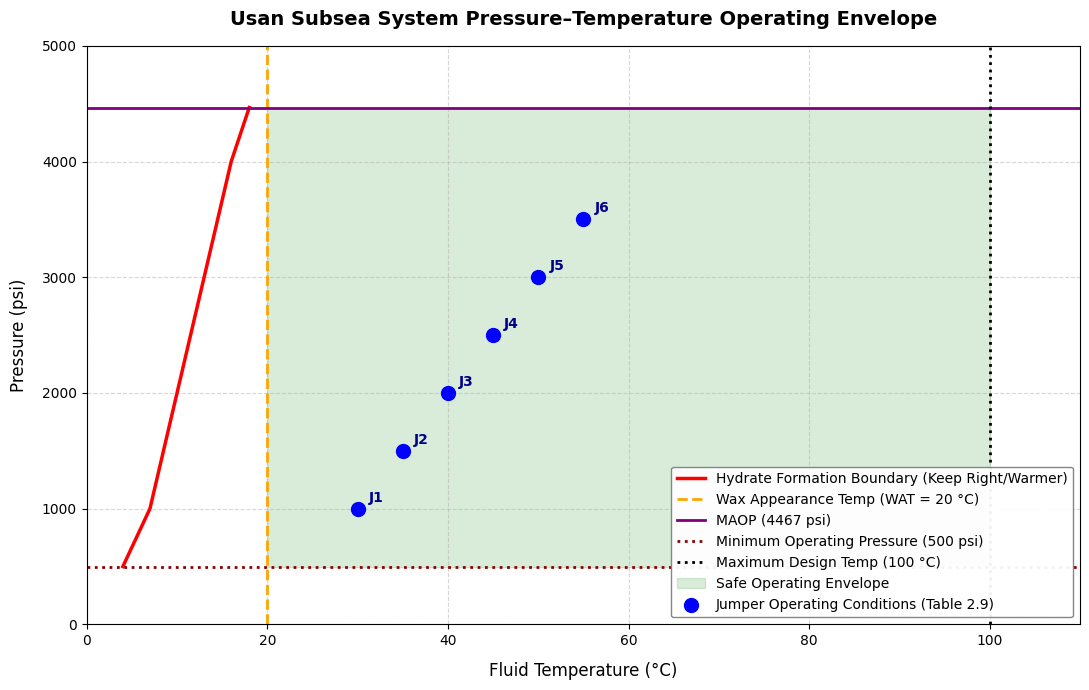

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

MAOP_PSI = 4467
min_pressure_psi = 500
max_temperature_c = 100
wat_c = 20

#Hydrate formation boundary curve data
hydrate_pressure = np.array([500, 1000, 2000, 3000, 4000, 4467])
hydrate_temperature = np.array([4, 7, 10, 13, 16, 18])

#Jumper operating points from Table 2.9
jumper_data = pd.DataFrame({
    "Jumper": ["J1", "J2", "J3", "J4", "J5", "J6"],
    "Pressure_psi": [1000, 1500, 2000, 2500, 3000, 3500],
    "Temperature_C": [30, 35, 40, 45, 50, 55]
})

fig, ax = plt.subplots(figsize=(11, 7))

#Plot the Hydrate Boundary Curve
ax.plot(
    hydrate_temperature,
    hydrate_pressure,
    color="red",
    linestyle="-",
    linewidth=2.5,
    label="Hydrate Formation Boundary (Keep Right/Warmer)"
)

#Draw wax appearance temperature limit line (WAT)
ax.axvline(
    x=wat_c,
    color="orange",
    linestyle="--",
    linewidth=2,
    label=f"Wax Appearance Temp (WAT = {wat_c} °C)"
)

#Draw upper mechanical pressure limit line (MAOP)
ax.axhline(
    y=MAOP_PSI,
    color="purple",
    linestyle="-",
    linewidth=2,
    label=f"MAOP ({MAOP_PSI} psi)"
)

#Draw lower mechanical pressure limit line
ax.axhline(
    y=min_pressure_psi,
    color="darkred",
    linestyle=":",
    linewidth=2,
    label=f"Minimum Operating Pressure ({min_pressure_psi} psi)"
)

#Draw maximum thermal design limit line
ax.axvline(
    x=max_temperature_c,
    color="black",
    linestyle=":",
    linewidth=2,
    label=f"Maximum Design Temp ({max_temperature_c} °C)"
)

#Highlight Safe Operating Region (Shading)
t_space = np.linspace(wat_c, max_temperature_c, 100)
p_min = np.full_like(t_space, min_pressure_psi)
p_max = np.full_like(t_space, MAOP_PSI)

#Calculate hydrate temperature limit interpolated across our pressure window for shading
hydrate_temp_interp = np.interp(p_min, hydrate_pressure, hydrate_temperature)

ax.fill_betweenx(
    y=[min_pressure_psi, MAOP_PSI],
    x1=max(wat_c, hydrate_temperature.max()),
    x2=max_temperature_c,
    color="green",
    alpha=0.15,
    label="Safe Operating Envelope"
)

#Plot current operating points
scatter = ax.scatter(
    jumper_data["Temperature_C"],
    jumper_data["Pressure_psi"],
    color="blue",
    marker="o",
    s=100,
    zorder=5,
    label="Jumper Operating Conditions (Table 2.9)"
)

#Label each jumper point on the graph
for _, point in jumper_data.iterrows():
    ax.annotate(
        point["Jumper"],
        (point["Temperature_C"], point["Pressure_psi"]),
        xytext=(8, 5),
        textcoords="offset points",
        fontsize=10,
        weight="bold",
        color="darkblue"
    )

#Plot configuration and styling
ax.set_title("Usan Subsea System Pressure–Temperature Operating Envelope", fontsize=14, pad=15, weight="bold")
ax.set_xlabel("Fluid Temperature (°C)", fontsize=12, labelpad=10)
ax.set_ylabel("Pressure (psi)", fontsize=12, labelpad=10)
ax.set_xlim(0, 110)
ax.set_ylim(0, 5000)
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(loc="lower right", framealpha=0.95, edgecolor="gray")

plt.tight_layout()
plt.show()

The code creates the graph structure. It uses  labelled illustrative hydrate-curve values and placeholder operating points. MAOP( Operating pressure must not exceed 4,467 psi), Hydrate curve (The operating temperature must be above the applicable hydrate-formation temperature at the operating pressure), WAT line (The operating temperature must be above WAT if the design criterion requires avoiding wax formation) Minimum pressure (Operating pressure must remain above the specified lower threshold) Maximum temperature (Operating temperature must remain below the material's allowable temperature limit). The safe region is the intersection of all applicable constraints.

Q3. Extend to a 3-parameter envelope (P-T-flow rate) and create a 3D scatter plot showing operating points coloured by envelope status.

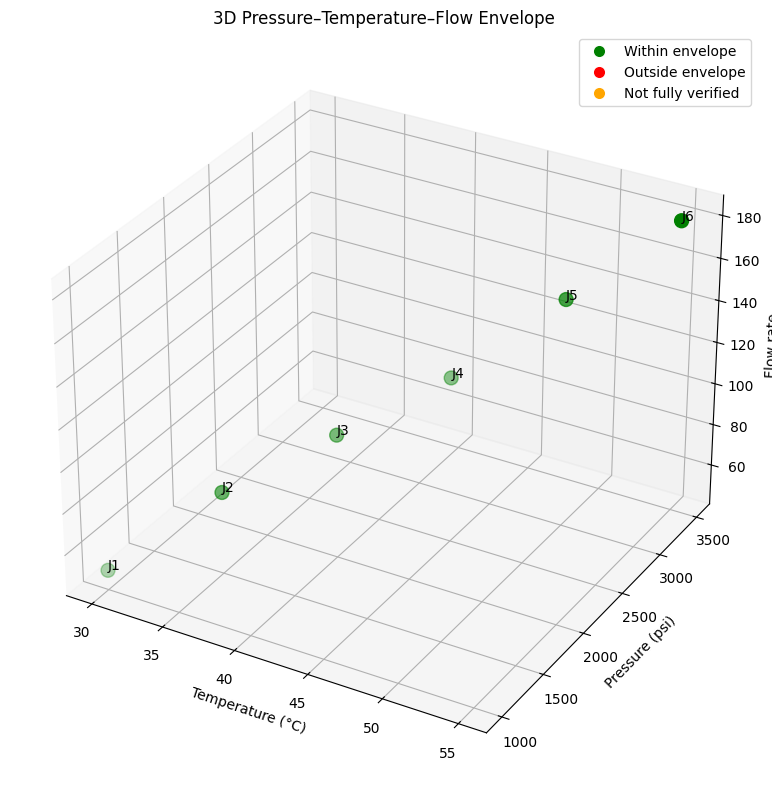

  Jumper  Pressure_psi  Temperature_C  Flow_rate           Status
0     J1          1000             30         50  WITHIN ENVELOPE
1     J2          1500             35         80  WITHIN ENVELOPE
2     J3          2000             40        100  WITHIN ENVELOPE
3     J4          2500             45        120  WITHIN ENVELOPE
4     J5          3000             50        150  WITHIN ENVELOPE
5     J6          3500             55        180  WITHIN ENVELOPE


In [10]:
from mpl_toolkits.mplot3d import Axes3D

MIN_FLOW = 10
MAX_FLOW = 200

operating_data = pd.DataFrame({
    "Jumper": ["J1", "J2", "J3", "J4", "J5", "J6"],
    "Pressure_psi": [1000, 1500, 2000, 2500, 3000, 3500],
    "Temperature_C": [30, 35, 40, 45, 50, 55],
    "Flow_rate": [50, 80, 100, 120, 150, 180]
})

results = []

for _, row in operating_data.iterrows():

    hydrate_temp = np.interp(
        row["Pressure_psi"],
        hydrate_pressure,
        hydrate_temperature
    )

    result = pressure_temperature_envelope(
        pressure_psi=row["Pressure_psi"],
        temperature_c=row["Temperature_C"],
        flow_rate=row["Flow_rate"],
        maop_psi=MAOP_PSI,
        min_pressure_psi=min_pressure_psi,
        max_temperature_c=max_temperature_c,
        wat_c=wat_c,
        hydrate_temperature_c=hydrate_temp,
        min_flow_rate=MIN_FLOW,
        max_flow_rate=MAX_FLOW
    )

    results.append(result["status"])

operating_data["Status"] = results

colour_map = {
    "WITHIN ENVELOPE": "green",
    "OUTSIDE ENVELOPE": "red",
    "INCOMPLETE - NOT FULLY VERIFIED": "orange"
}

point_colours = operating_data["Status"].map(colour_map)

fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(
    operating_data["Temperature_C"],
    operating_data["Pressure_psi"],
    operating_data["Flow_rate"],
    c=point_colours,
    s=100
)

for _, row in operating_data.iterrows():
    ax.text(
        row["Temperature_C"],
        row["Pressure_psi"],
        row["Flow_rate"],
        row["Jumper"]
    )

ax.set_title("3D Pressure–Temperature–Flow Envelope")
ax.set_xlabel("Temperature (°C)")
ax.set_ylabel("Pressure (psi)")
ax.set_zlabel("Flow rate")

from matplotlib.lines import Line2D

legend_items = [
    Line2D([0], [0], marker="o", color="w",
           markerfacecolor="green", label="Within envelope",
           markersize=9),
    Line2D([0], [0], marker="o", color="w",
           markerfacecolor="red", label="Outside envelope",
           markersize=9),
    Line2D([0], [0], marker="o", color="w",
           markerfacecolor="orange",
           label="Not fully verified", markersize=9)
]

ax.legend(handles=legend_items)
plt.tight_layout()
plt.show()

print(operating_data[
    ["Jumper", "Pressure_psi", "Temperature_C",
     "Flow_rate", "Status"]
])

The np.interp() function estimates the hydrate-formation temperature at each operating pressure using the supplied curve data. Each jumper is then checked against the limits. Green means all configured limits passed, Red means at least one limit failed and Orange means no configured limit failed, but one or more limits remain unverified. These colours represent the example code's classifications, not a certified safety assessment. The hydrate curve and flow-rate limits must be replaced with validated values before interpreting real operating conditions.

Q4.
Write a function that takes a DataFrame of operating data and returns the percentage of time each parameter was within the design envelope.

In [23]:
def percentage_within_envelope(
    df,
    maop_psi=4467,
    min_pressure_psi=None,
    max_temperature_c=None,
    wat_c=None,
    min_flow_rate=None,
    max_flow_rate=None,
    hydrate_curve=None
):
    """
    Calculate the percentage of operating observations that
    meet individual design limits and all configured checks.

    Required DataFrame columns:
        Pressure_psi
        Temperature_C
        Flow_rate

    hydrate_curve:
        Optional tuple (pressure_array, temperature_array)
        containing approved hydrate equilibrium data.

    Returns
    -------
    pandas.Series
        Percentage within each check and the overall envelope.
    """

    required_columns = [
        "Pressure_psi",
        "Temperature_C",
        "Flow_rate"
    ]

    missing_columns = [
        col for col in required_columns if col not in df.columns
    ]

    if missing_columns:
        raise ValueError(
            f"Missing required columns: {missing_columns}"
        )

    if df.empty:
        raise ValueError("The DataFrame is empty.")

    data = df[required_columns].copy()

    for col in required_columns:
        data[col] = pd.to_numeric(data[col], errors="raise")

    if not np.isfinite(data.to_numpy(dtype=float)).all():
        raise ValueError(
            "Operating data contains missing or non-finite values."
        )

    if (data["Pressure_psi"] < 0).any():
        raise ValueError("Pressure cannot be negative.")

    if (data["Flow_rate"] < 0).any():
        raise ValueError("Flow rate cannot be negative.")

    checks = {
        "Pressure within MAOP": (
            data["Pressure_psi"] <= maop_psi
        )
    }

    if min_pressure_psi is not None:
        checks["Pressure above minimum"] = (
            data["Pressure_psi"] >= min_pressure_psi
        )

    if max_temperature_c is not None:
        checks["Temperature below maximum"] = (
            data["Temperature_C"] <= max_temperature_c
        )

    if wat_c is not None:
        checks["Temperature above WAT"] = (
            data["Temperature_C"] > wat_c
        )

    if min_flow_rate is not None:
        checks["Flow above minimum"] = (
            data["Flow_rate"] >= min_flow_rate
        )

    if max_flow_rate is not None:
        checks["Flow below maximum"] = (
            data["Flow_rate"] <= max_flow_rate
        )

    if hydrate_curve is not None:
        p_curve, t_curve = hydrate_curve

        if (len(p_curve) != len(t_curve)
                or len(p_curve) < 2):
            raise ValueError(
                "Hydrate curve arrays must have equal lengths "
                "and at least two points."
            )

        p_curve = np.asarray(p_curve, dtype=float)
        t_curve = np.asarray(t_curve, dtype=float)

        if not (
            np.isfinite(p_curve).all()
            and np.isfinite(t_curve).all()
        ):
            raise ValueError(
                "Hydrate curve contains non-finite values."
            )

        if (p_curve < 0).any():
            raise ValueError(
                "Hydrate curve pressure cannot be negative."
            )

        if not np.all(np.diff(p_curve) > 0):
            raise ValueError(
                "Hydrate curve pressures must be strictly increasing."
            )

        if ((data["Pressure_psi"] < p_curve.min()).any()
                or (data["Pressure_psi"] > p_curve.max()).any()):
            raise ValueError(
                "Operating pressures fall outside the supplied "
                "hydrate curve range; extrapolation is not allowed."
            )

        hydrate_temps = np.interp(
            data["Pressure_psi"],
            p_curve,
            t_curve
        )

        checks["Temperature above hydrate curve"] = (
            data["Temperature_C"].to_numpy() > hydrate_temps
        )

    percentages = {
        name: round(mask.mean() * 100, 2)
        for name, mask in checks.items()
    }

    all_checks = pd.DataFrame(checks).all(axis=1)

    percentages["Overall within configured envelope"] = round(
        all_checks.mean() * 100, 2
    )

    return pd.Series(percentages, name="Percentage (%)")

summary = percentage_within_envelope(
    operating_data,
    maop_psi=MAOP_PSI,
    min_pressure_psi=min_pressure_psi,
    max_temperature_c=max_temperature_c,
    wat_c=wat_c,
    min_flow_rate=MIN_FLOW,
    max_flow_rate=MAX_FLOW,
    hydrate_curve=(hydrate_pressure, hydrate_temperature)
)

print("=" * 40)
print(summary)

Pressure within MAOP                  100.0
Pressure above minimum                100.0
Temperature below maximum             100.0
Temperature above WAT                 100.0
Flow above minimum                    100.0
Flow below maximum                    100.0
Temperature above hydrate curve       100.0
Overall within configured envelope    100.0
Name: Percentage (%), dtype: float64


The output shows the percentage of observations that satisfy each configured check, followed by the overall compliance percentage. This function assumes that each row is one observation and that all rows have equal weight. If observations are irregularly spaced in time, calculate time-weighted percentages instead. Missing measurements are rejected rather than silently counted as safe.